# PRCP-1001 – Rice Leaf Disease Detection

## Capstone Project – Complete Data Analysis, Model Comparison & Challenge Report

### Problem Statement
Develop an image classification system capable of identifying three major rice leaf diseases from infected leaf images.

### Dataset
The supplied dataset contains 120 JPG images distributed equally across three classes:

- Leaf Smut
- Brown Spot
- Bacterial Leaf Blight

> **Dataset note:** The project description mentions "leaf blast" in one place, while the supplied class list contains **Leaf Smut**. This notebook follows the actual dataset class labels.

### Tasks Covered
1. Complete data analysis of the dataset.
2. Build models to classify the three disease classes.
3. Analyze data augmentation and other techniques.
4. Compare multiple models.
5. Recommend the best model for production.
6. Document challenges and the techniques used to address them.

**Important limitation:** The dataset is very small (40 images per class). Therefore, high accuracy on this dataset should not automatically be interpreted as production-level generalization.

## 1. Import Required Libraries

In [1]:
# If needed, uncomment the following line in Google Colab/Jupyter:
# %pip install -q tensorflow seaborn scikit-learn pandas matplotlib pillow

import os
import zipfile
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50, EfficientNetB0
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: []


## 2. Download and Extract the Dataset

The next cell downloads the project ZIP directly from the supplied dataset URL. If you already have the ZIP, you can set `LOCAL_ZIP_PATH` instead.

In [2]:
import urllib.request

DATASET_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"

BASE_DIR = Path.cwd() / "PRCP_1001_RiceLeaf"
BASE_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = BASE_DIR / "RiceLeaf.zip"
EXTRACT_DIR = BASE_DIR / "extracted"

# Optional: set this to an existing ZIP file if you already downloaded it.
LOCAL_ZIP_PATH = None

if LOCAL_ZIP_PATH is not None:
    local_path = Path(LOCAL_ZIP_PATH)
    if not local_path.exists():
        raise FileNotFoundError(f"LOCAL_ZIP_PATH does not exist: {local_path}")
    ZIP_PATH = local_path
    print("Using local ZIP:", ZIP_PATH)
elif not ZIP_PATH.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
    print("Download complete:", ZIP_PATH)
else:
    print("ZIP already exists:", ZIP_PATH)

if not EXTRACT_DIR.exists() or not any(EXTRACT_DIR.iterdir()):
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
    print("Dataset extracted to:", EXTRACT_DIR)
else:
    print("Dataset already extracted:", EXTRACT_DIR)

# Show a concise directory summary.
for root, dirs, files in os.walk(EXTRACT_DIR):
    level = str(root).replace(str(EXTRACT_DIR), "").count(os.sep)
    indent = "  " * level
    image_files = [f for f in files if Path(f).suffix.lower() in image_extensions] if "image_extensions" in globals() else []
    print(f"{indent}{Path(root).name}/")
    if image_files:
        print(f"{indent}  {len(image_files)} image file(s)")

Download complete: /content/PRCP_1001_RiceLeaf/RiceLeaf.zip
Dataset extracted to: /content/PRCP_1001_RiceLeaf/extracted
extracted/
  Data/


In [12]:
# Extract individual class archives
data_base_path = EXTRACT_DIR / "Data"

# Mapping from zip file prefix (lowercase) to actual class name
zip_prefix_to_class = {cls.lower(): cls for cls in EXPECTED_CLASSES}

if data_base_path.exists() and data_base_path.is_dir():
    print(f"Processing archives in: {data_base_path}")
    for item in data_base_path.iterdir():
        if item.is_file() and item.suffix.lower() == ".zip":
            # Example: "Brown spot-20200814T055208Z-001.zip" -> "Brown spot"
            zip_class_prefix = item.stem.split('-')[0].strip().lower()

            target_class_name = zip_prefix_to_class.get(zip_class_prefix)

            if target_class_name:
                target_extract_path = data_base_path / target_class_name
                # Check if the target directory exists and is not empty
                if not target_extract_path.exists() or not any(target_extract_path.iterdir()):
                    print(f"Unzipping {item.name} to {target_extract_path}...")
                    target_extract_path.mkdir(parents=True, exist_ok=True)
                    with zipfile.ZipFile(item, "r") as z:
                        z.extractall(target_extract_path)
                    print(f"Extracted {item.name}")
                else:
                    print(f"Skipping {item.name}, already extracted to {target_extract_path}.")
            else:
                print(f"Could not map zip file '{item.name}' with prefix '{zip_class_prefix}' to an expected class. Skipping.")
elif not data_base_path.exists():
    print(f"Base data path '{data_base_path}' not found. Skipping class archive extraction.")
else:
    print(f"Base data path '{data_base_path}' is not a directory. Skipping class archive extraction.")

# Verify the new structure
print("\nUpdated directory structure after class archive extraction:")
for root, dirs, files in os.walk(EXTRACT_DIR):
    level = str(root).replace(str(EXTRACT_DIR), "").count(os.sep)
    indent = "  " * level
    file_count = sum(1 for f in files if Path(f).suffix.lower() in image_extensions) if "image_extensions" in globals() else 0
    dir_count = len(dirs)

    components = []
    if dir_count > 0:
        components.append(f"{dir_count} dirs")
    if file_count > 0:
        components.append(f"{file_count} image files")

    extra_info = f" ({', '.join(components)})" if components else ""
    print(f"{indent}{Path(root).name}/{extra_info}")


Processing archives in: /content/PRCP_1001_RiceLeaf/extracted/Data
Skipping Brown spot-20200814T055208Z-001.zip, already extracted to /content/PRCP_1001_RiceLeaf/extracted/Data/Brown Spot.
Skipping Leaf smut-20200814T055530Z-001.zip, already extracted to /content/PRCP_1001_RiceLeaf/extracted/Data/Leaf Smut.
Skipping Bacterial leaf blight-20200814T055237Z-001.zip, already extracted to /content/PRCP_1001_RiceLeaf/extracted/Data/Bacterial Leaf Blight.

Updated directory structure after class archive extraction:
extracted/ (1 dirs)
  Data/ (3 dirs)
    Leaf Smut/ (1 dirs)
      Leaf smut/ (39 image files)
    Bacterial Leaf Blight/ (1 dirs)
      Bacterial leaf blight/ (40 image files)
    Brown Spot/ (1 dirs)
      Brown spot/ (40 image files)


## 3. Locate the Class Folders

In [9]:
EXPECTED_CLASSES = ["Leaf Smut", "Brown Spot", "Bacterial Leaf Blight"]

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Find directories containing image files
candidate_dirs = []
for root, dirs, files in os.walk(EXTRACT_DIR):
    image_count = sum(Path(f).suffix.lower() in image_extensions for f in files)
    if image_count > 0:
        candidate_dirs.append((Path(root), image_count))

print("Directories containing images:")
for path, count in candidate_dirs:
    print(f"{count:3d} images -> {path}")

# Try to locate folders matching expected class names.
class_dirs = {}
for cls in EXPECTED_CLASSES:
    matches = []
    for root, dirs, files in os.walk(EXTRACT_DIR):
        if Path(root).name.strip().lower() == cls.lower():
            matches.append(Path(root))
    if matches:
        class_dirs[cls] = matches[0]

print("\nDetected class folders:")
for cls, path in class_dirs.items():
    print(f"{cls}: {path}")

# Fallback: identify a directory whose immediate subdirectories resemble the classes.
if len(class_dirs) != 3:
    print("\nAutomatic class-folder matching was incomplete.")
    print("If required, manually set CLASS_DIRS in the next cell.")

Directories containing images:
 39 images -> /content/PRCP_1001_RiceLeaf/extracted/Data/Leaf Smut/Leaf smut
 40 images -> /content/PRCP_1001_RiceLeaf/extracted/Data/Bacterial Leaf Blight/Bacterial leaf blight
 40 images -> /content/PRCP_1001_RiceLeaf/extracted/Data/Brown Spot/Brown spot

Detected class folders:
Leaf Smut: /content/PRCP_1001_RiceLeaf/extracted/Data/Leaf Smut
Brown Spot: /content/PRCP_1001_RiceLeaf/extracted/Data/Brown Spot
Bacterial Leaf Blight: /content/PRCP_1001_RiceLeaf/extracted/Data/Bacterial Leaf Blight


## 4. Configure Dataset Paths

In [10]:

CLASS_DIRS = {
    "Leaf Smut": Path("/path/to/Leaf Smut"),
    "Brown Spot": Path("/path/to/Brown Spot"),
    "Bacterial Leaf Blight": Path("/path/to/Bacterial Leaf Blight")
 }



if len(CLASS_DIRS) != 3:
    raise ValueError(
        "Could not automatically locate all 3 class folders. "
        "Please set CLASS_DIRS manually in this cell and rerun it."
    )

print("Using:")
for cls, path in CLASS_DIRS.items():
    print(f"{cls}: {path}")

Using:
Leaf Smut: /path/to/Leaf Smut
Brown Spot: /path/to/Brown Spot
Bacterial Leaf Blight: /path/to/Bacterial Leaf Blight


## 5. Create a Dataset DataFrame

This section performs the initial data audit, including file paths, labels, image dimensions, channels, and file validity.

In [13]:
BASE_DATA_DIR = EXTRACT_DIR / "Data"
CLASS_DIRS = {
    "Leaf Smut": BASE_DATA_DIR / "Leaf Smut" / "Leaf smut",
    "Brown Spot": BASE_DATA_DIR / "Brown Spot" / "Brown spot",
    "Bacterial Leaf Blight": BASE_DATA_DIR / "Bacterial Leaf Blight" / "Bacterial leaf blight"
}

records = []

for label, folder in CLASS_DIRS.items():
    for file_path in sorted(folder.iterdir()):
        if file_path.is_file() and file_path.suffix.lower() in image_extensions:
            records.append({
                "filepath": str(file_path),
                "filename": file_path.name,
                "label": label
            })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No image files were found in the detected class folders.")

print("Total image files:", len(df))
display(df.head())

print("\nClass distribution:")
display(
    df["label"]
    .value_counts()
    .reindex(EXPECTED_CLASSES, fill_value=0)
    .rename_axis("Class")
    .to_frame("Images")
)

print("\nDuplicate file paths:", df["filepath"].duplicated().sum())

Total image files: 119


,filepath,filename,label
0,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0293.JPG,Leaf Smut
1,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0308.JPG,Leaf Smut
2,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0309.JPG,Leaf Smut
3,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0310.JPG,Leaf Smut
4,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0312.JPG,Leaf Smut



Class distribution:


,Images
Class,
Leaf Smut,39
Brown Spot,40
Bacterial Leaf Blight,40



Duplicate file paths: 0


In [14]:
# Validate images and collect dimensions
valid_records = []
invalid_files = []

for _, row in df.iterrows():
    try:
        with Image.open(row["filepath"]) as img:
            valid_records.append({
                **row.to_dict(),
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "format": img.format
            })
    except Exception as e:
        invalid_files.append((row["filepath"], str(e)))

image_df = pd.DataFrame(valid_records)

print("Valid images:", len(image_df))
print("Invalid/corrupt images:", len(invalid_files))

if invalid_files:
    print("\nInvalid files:")
    for item in invalid_files:
        print(item)

display(image_df.head())

Valid images: 119
Invalid/corrupt images: 0


,filepath,filename,label,width,height,mode,format
0,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0293.JPG,Leaf Smut,3081,897,RGB,JPEG
1,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0308.JPG,Leaf Smut,3081,897,RGB,JPEG
2,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0309.JPG,Leaf Smut,3081,897,RGB,JPEG
3,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0310.JPG,Leaf Smut,3081,897,RGB,JPEG
4,/content/PRCP_1001_RiceLeaf/extracted/Data/Lea...,DSC_0312.JPG,Leaf Smut,3081,897,RGB,JPEG


## 6. Exploratory Data Analysis – Class Distribution

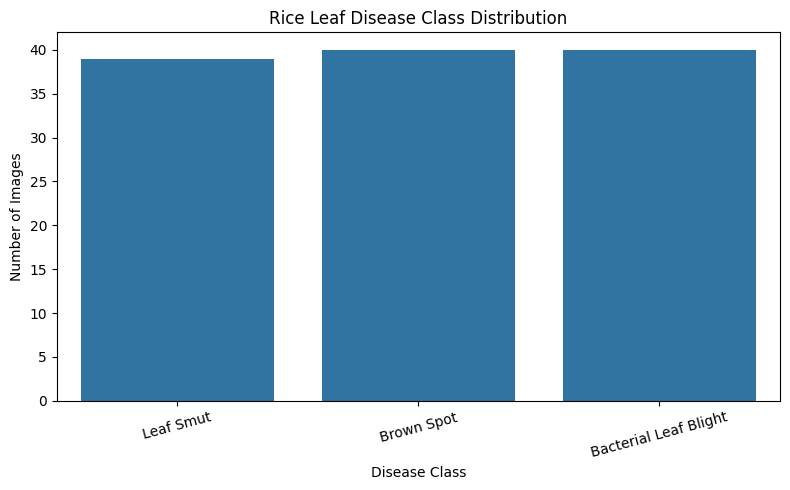

In [15]:
plt.figure(figsize=(8, 5))
sns.countplot(data=image_df, x="label", order=EXPECTED_CLASSES)
plt.title("Rice Leaf Disease Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [16]:
class_counts = image_df["label"].value_counts()
print("Class balance:")
display(class_counts.rename_axis("Class").to_frame("Count"))

print("Minimum class size:", class_counts.min())
print("Maximum class size:", class_counts.max())

if class_counts.nunique() == 1:
    print("The dataset is perfectly balanced by class count.")
else:
    print("The dataset is imbalanced and may require class weighting or resampling.")

Class balance:


,Count
Class,
Brown Spot,40
Bacterial Leaf Blight,40
Leaf Smut,39


Minimum class size: 39
Maximum class size: 40
The dataset is imbalanced and may require class weighting or resampling.


## 7. Image Dimension Analysis

Image dimension statistics:


,width,height
count,119.000000,119.000000
mean,2383.638655,707.739496
std,1123.528972,311.657582
min,250.000000,71.000000
25%,1074.000000,377.000000
50%,3081.000000,897.000000
75%,3081.000000,897.000000
max,3081.000000,900.000000


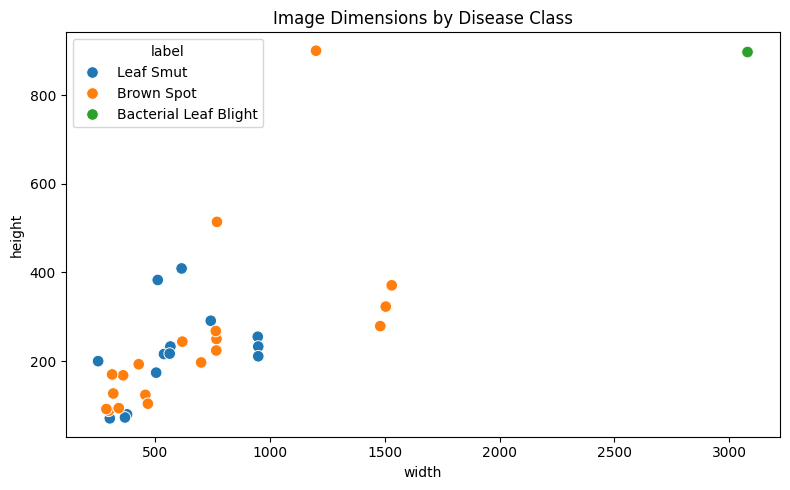

In [17]:
print("Image dimension statistics:")
display(image_df[["width", "height"]].describe())

plt.figure(figsize=(8, 5))
sns.scatterplot(data=image_df, x="width", y="height", hue="label", s=70)
plt.title("Image Dimensions by Disease Class")
plt.tight_layout()
plt.show()

## 8. Visualize Representative Samples

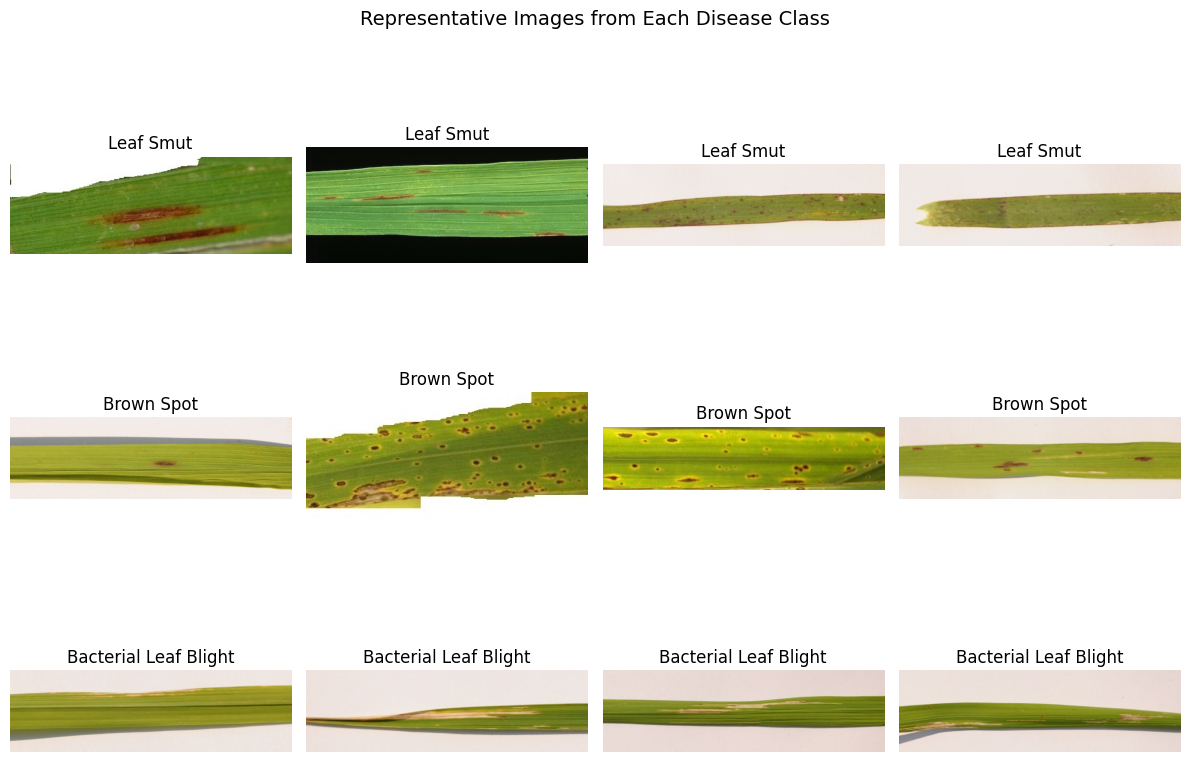

In [18]:
fig, axes = plt.subplots(len(EXPECTED_CLASSES), 4, figsize=(12, 9), squeeze=False)

for row_idx, cls in enumerate(EXPECTED_CLASSES):
    class_samples = image_df[image_df["label"] == cls]
    n_samples = min(4, len(class_samples))

    if n_samples > 0:
        samples = class_samples.sample(n=n_samples, random_state=SEED)
        for col_idx, (_, row) in enumerate(samples.iterrows()):
            img = Image.open(row["filepath"]).convert("RGB")
            axes[row_idx, col_idx].imshow(img)
            axes[row_idx, col_idx].set_title(cls)
            axes[row_idx, col_idx].axis("off")

    for col_idx in range(n_samples, 4):
        axes[row_idx, col_idx].axis("off")

plt.suptitle("Representative Images from Each Disease Class", fontsize=14)
plt.tight_layout()
plt.show()

## 9. Data Quality Checks

In [19]:
print("Missing values:")
display(image_df.isnull().sum().to_frame("Missing"))

print("Duplicate file paths:", image_df["filepath"].duplicated().sum())

print("\nImage modes:")
display(image_df["mode"].value_counts().rename_axis("Mode").to_frame("Count"))

print("\nImage formats:")
display(image_df["format"].value_counts().rename_axis("Format").to_frame("Count"))

print("\nZero/invalid dimensions:")
print(((image_df["width"] <= 0) | (image_df["height"] <= 0)).sum())

Missing values:


,Missing
filepath,0
filename,0
label,0
width,0
height,0
mode,0
format,0


Duplicate file paths: 0

Image modes:


,Count
Mode,
RGB,119



Image formats:


,Count
Format,
JPEG,119



Zero/invalid dimensions:
0


## 10. Train / Validation / Test Split

A stratified split preserves the class proportions. Because the dataset is very small, the test set is also small; this limitation is discussed later.

In [20]:
# 70% train, 15% validation, 15% test
train_df, temp_df = train_test_split(
    image_df,
    test_size=0.30,
    stratify=image_df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTrain distribution:")
display(train_df["label"].value_counts().rename_axis("Class").to_frame("Count"))

print("\nValidation distribution:")
display(val_df["label"].value_counts().rename_axis("Class").to_frame("Count"))

print("\nTest distribution:")
display(test_df["label"].value_counts().rename_axis("Class").to_frame("Count"))

Train: 83
Validation: 18
Test: 18

Train distribution:


,Count
Class,
Brown Spot,28
Bacterial Leaf Blight,28
Leaf Smut,27



Validation distribution:


,Count
Class,
Leaf Smut,6
Brown Spot,6
Bacterial Leaf Blight,6



Test distribution:


,Count
Class,
Leaf Smut,6
Brown Spot,6
Bacterial Leaf Blight,6


## 11. Data Augmentation Analysis

Data augmentation creates realistic variations of training images. It can reduce overfitting when the dataset is small.

Techniques investigated:
- Rotation
- Width/height translation
- Zoom
- Horizontal flip
- Shear

Augmentation is applied **only to training data**, not validation/test data.

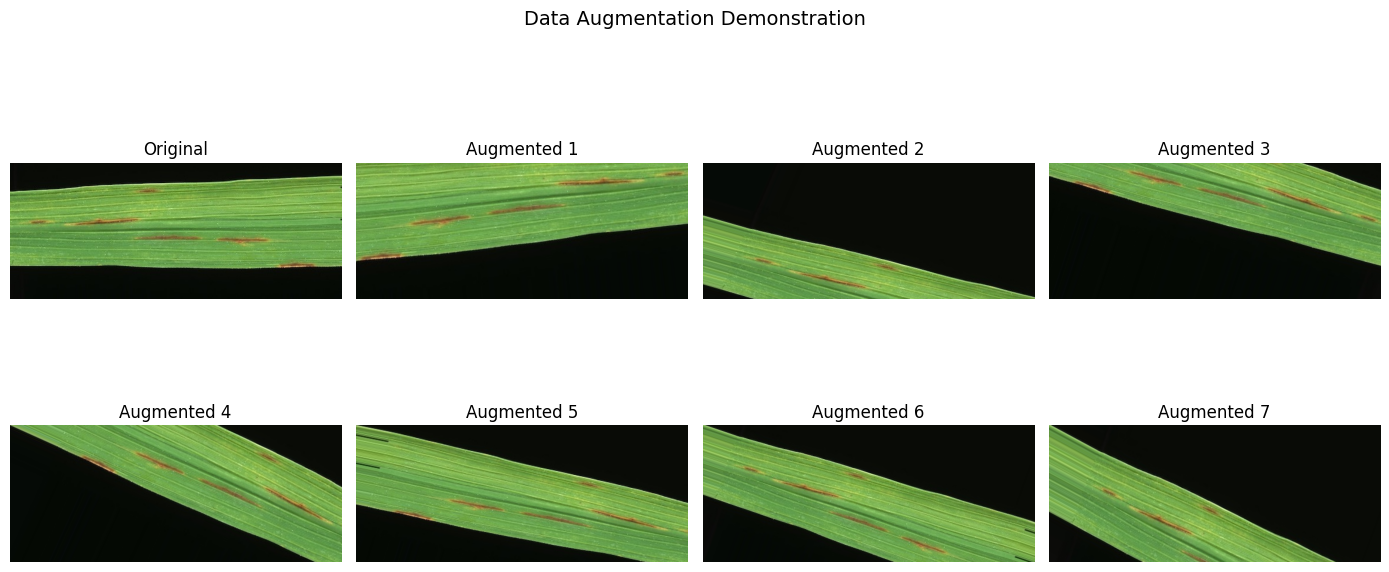

In [21]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
NUM_CLASSES = 3

train_datagen_aug = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.20,
    shear_range=0.10,
    horizontal_flip=True,
    fill_mode="nearest"
)

eval_datagen = ImageDataGenerator(rescale=1./255)

# Demonstrate augmentation on one image
demo_path = train_df.iloc[0]["filepath"]
demo_img = Image.open(demo_path).convert("RGB")
demo_array = np.array(demo_img)

aug_iter = train_datagen_aug.flow(
    np.expand_dims(demo_array, axis=0),
    batch_size=1,
    seed=SEED
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow(demo_img)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

for i in range(7):
    aug_img = next(aug_iter)[0]
    ax = axes.flat[i + 1]
    ax.imshow(aug_img)
    ax.set_title(f"Augmented {i+1}")
    ax.axis("off")

plt.suptitle("Data Augmentation Demonstration", fontsize=14)
plt.tight_layout()
plt.show()

## 12. Create Keras Data Generators

In [22]:
def create_generators(model_name):
    # All pretrained models receive their expected ImageNet preprocessing.
    # The custom CNN uses simple 0-1 rescaling.
    if model_name == "Custom CNN":
        preprocess_function = lambda x: x / 255.0
    elif model_name == "MobileNetV2":
        preprocess_function = mobilenet_preprocess
    elif model_name == "ResNet50":
        preprocess_function = resnet_preprocess
    elif model_name == "EfficientNetB0":
        # EfficientNetB0 includes its preprocessing layer when include_preprocessing=True.
        # Therefore raw 0-255 pixel values are passed to the model.
        preprocess_function = None
    else:
        raise ValueError(f"Unknown model: {model_name}")

    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_function,
        rotation_range=25,
        width_shift_range=0.15,
        height_shift_range=0.15,
        zoom_range=0.20,
        shear_range=0.10,
        horizontal_flip=True,
        fill_mode="nearest"
    )

    eval_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_function
    )

    train_generator = train_datagen.flow_from_dataframe(
        train_df,
        x_col="filepath",
        y_col="label",
        target_size=IMG_SIZE,
        class_mode="categorical",
        classes=EXPECTED_CLASSES,
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=SEED
    )

    val_generator = eval_datagen.flow_from_dataframe(
        val_df,
        x_col="filepath",
        y_col="label",
        target_size=IMG_SIZE,
        class_mode="categorical",
        classes=EXPECTED_CLASSES,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_generator = eval_datagen.flow_from_dataframe(
        test_df,
        x_col="filepath",
        y_col="label",
        target_size=IMG_SIZE,
        class_mode="categorical",
        classes=EXPECTED_CLASSES,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    return train_generator, val_generator, test_generator

print("Model-specific generators will be created during training and evaluation.")

Model-specific generators will be created during training and evaluation.


## 13. Define a Custom CNN Baseline

In [24]:
def build_custom_cnn(input_shape=(224, 224, 3), num_classes=3):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.40),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.30),
        layers.Dense(num_classes, activation="softmax")
    ])

    return model

## 14. Transfer Learning Models

Transfer learning uses representations learned from large image datasets. This is particularly appropriate here because the rice-leaf dataset contains only 120 images.

In [25]:
def build_transfer_model(base_model, input_shape=(224, 224, 3), num_classes=3):
    base_model.trainable = False

    inputs = keras.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    return model

models_to_build = {
    "Custom CNN": build_custom_cnn(),
    "MobileNetV2": build_transfer_model(
        MobileNetV2(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    ),
    "ResNet50": build_transfer_model(
        ResNet50(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    ),
    "EfficientNetB0": build_transfer_model(
        EfficientNetB0(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    )
}

for name, model in models_to_build.items():
    print(f"{name}: {model.count_params():,} parameters")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Custom CNN: 423,619 parameters
MobileNetV2: 2,261,827 parameters
ResNet50: 23,593,859 parameters
EfficientNetB0: 4,053,414 parameters


## 15. Training Configuration

In [26]:
EPOCHS = 30

def compile_model(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def get_callbacks():
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=3,
            min_lr=1e-7,
            verbose=1
        )
    ]

## 16. Train All Models

This cell may take several minutes depending on whether a GPU is available.

In [27]:
histories = {}
training_times = {}
generator_sets = {}

for name, model in models_to_build.items():
    print("\n" + "=" * 70)
    print("Training:", name)
    print("=" * 70)

    train_gen, val_gen, test_gen = create_generators(name)
    generator_sets[name] = (train_gen, val_gen, test_gen)

    compile_model(model)

    start = time.time()
    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=EPOCHS,
        callbacks=get_callbacks(),
        verbose=1
    )
    elapsed = time.time() - start

    histories[name] = history.history
    training_times[name] = elapsed

    print(f"{name} training time: {elapsed:.2f} seconds")


Training: Custom CNN
Found 83 validated image filenames belonging to 3 classes.
Found 18 validated image filenames belonging to 3 classes.
Found 18 validated image filenames belonging to 3 classes.
Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.3253 - loss: 1.4993 - val_accuracy: 0.3889 - val_loss: 1.0985 - learning_rate: 1.0000e-04
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.4940 - loss: 0.9997 - val_accuracy: 0.3333 - val_loss: 1.0980 - learning_rate: 1.0000e-04
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.5422 - loss: 0.8982 - val_accuracy: 0.3333 - val_loss: 1.0981 - learning_rate: 1.0000e-04
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.6988 - loss: 0.7299 - val_accuracy: 0.3333 - val_loss: 1.0996 - learning_rate: 1.0000e-04
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7432 - loss: 0.6892
Epoch 5: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
11/11 ━━━━━━━━━━━━━━━━━━━

## 17. Plot Training Curves

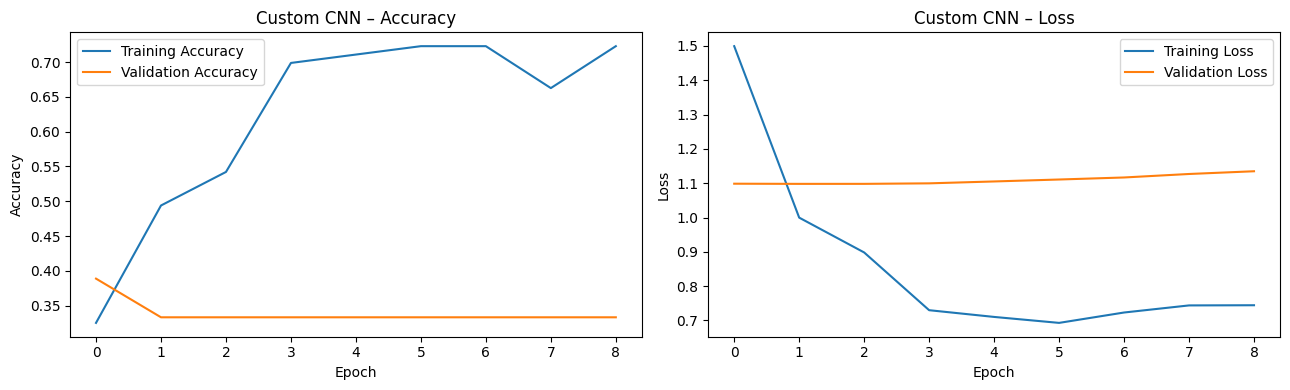

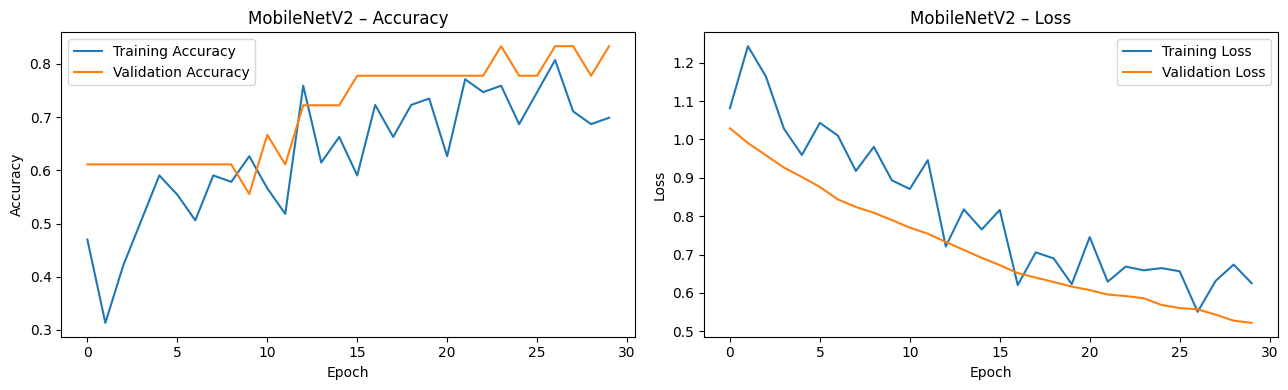

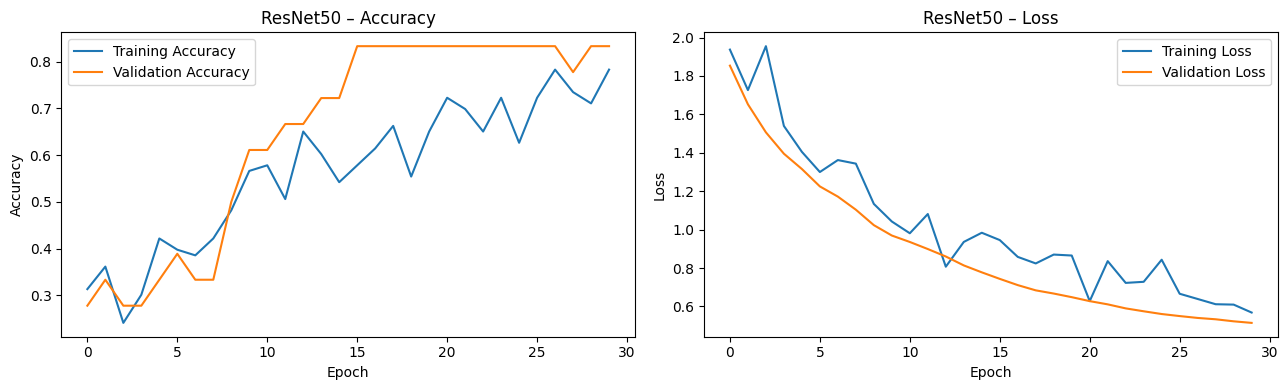

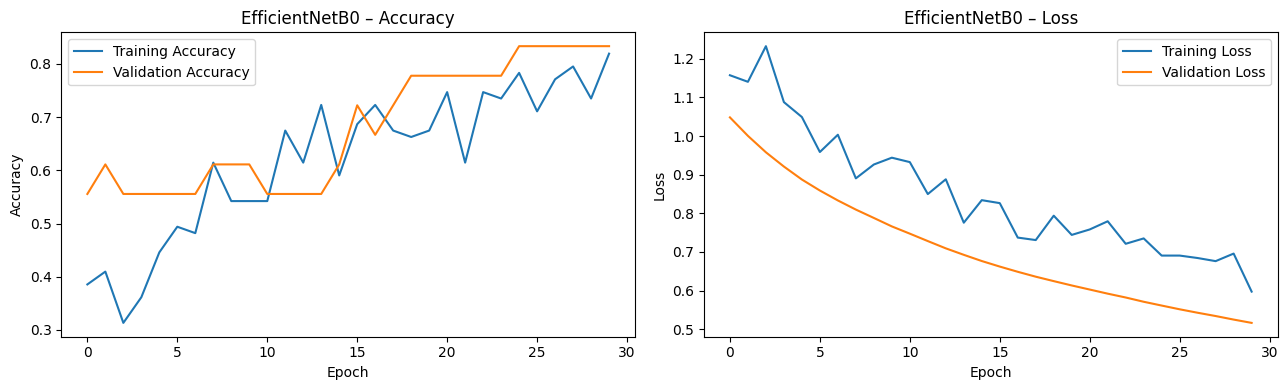

In [28]:
for name, history in histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(history["accuracy"], label="Training Accuracy")
    axes[0].plot(history["val_accuracy"], label="Validation Accuracy")
    axes[0].set_title(f"{name} – Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(history["loss"], label="Training Loss")
    axes[1].plot(history["val_loss"], label="Validation Loss")
    axes[1].set_title(f"{name} – Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## 18. Evaluate Models on the Test Set

In [29]:
def evaluate_model(model, generator, model_name):
    generator.reset()
    start = time.time()
    probabilities = model.predict(generator, verbose=0)
    total_inference_time = time.time() - start

    y_pred = np.argmax(probabilities, axis=1)
    y_true = generator.classes
    labels = EXPECTED_CLASSES

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    report = classification_report(
        y_true,
        y_pred,
        target_names=labels,
        zero_division=0
    )

    cm = confusion_matrix(y_true, y_pred)

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Inference Time (sec)": total_inference_time,
        "Inference Time per Image (sec)": total_inference_time / max(len(y_true), 1),
        "Parameters": model.count_params(),
        "Classification Report": report,
        "Confusion Matrix": cm,
        "y_true": y_true,
        "y_pred": y_pred,
        "probabilities": probabilities
    }

evaluation_results = {}

for name, model in models_to_build.items():
    _, _, test_gen = generator_sets[name]
    evaluation_results[name] = evaluate_model(model, test_gen, name)

metrics_rows = []
for name, result in evaluation_results.items():
    metrics_rows.append({
        "Model": name,
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1 Score": result["F1 Score"],
        "Parameters": result["Parameters"],
        "Inference Time (sec)": result["Inference Time (sec)"],
        "Inference Time per Image (sec)": result["Inference Time per Image (sec)"]
    })

results_df = pd.DataFrame(metrics_rows).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1 Score": "{:.4f}",
    "Inference Time (sec)": "{:.4f}",
    "Inference Time per Image (sec)": "{:.4f}"
}))

,Model,Accuracy,Precision,Recall,F1 Score,Parameters,Inference Time (sec),Inference Time per Image (sec)
0,ResNet50,0.9444,0.9524,0.9444,0.9441,23593859,7.9006,0.4389
1,MobileNetV2,0.7778,0.7746,0.7778,0.7723,2261827,3.5873,0.1993
2,EfficientNetB0,0.7222,0.7389,0.7222,0.7091,4053414,6.7819,0.3768
3,Custom CNN,0.3333,0.1111,0.3333,0.1667,423619,2.7198,0.1511


## 19. Classification Reports

In [30]:
for name, result in evaluation_results.items():
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print(result["Classification Report"])


Custom CNN
                       precision    recall  f1-score   support

            Leaf Smut       0.00      0.00      0.00         6
           Brown Spot       0.33      1.00      0.50         6
Bacterial Leaf Blight       0.00      0.00      0.00         6

             accuracy                           0.33        18
            macro avg       0.11      0.33      0.17        18
         weighted avg       0.11      0.33      0.17        18


MobileNetV2
                       precision    recall  f1-score   support

            Leaf Smut       0.80      0.67      0.73         6
           Brown Spot       0.67      0.67      0.67         6
Bacterial Leaf Blight       0.86      1.00      0.92         6

             accuracy                           0.78        18
            macro avg       0.77      0.78      0.77        18
         weighted avg       0.77      0.78      0.77        18


ResNet50
                       precision    recall  f1-score   support

            L

## 20. Confusion Matrices

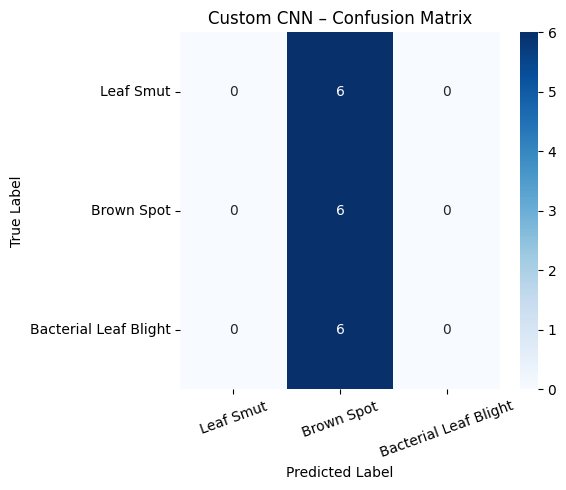

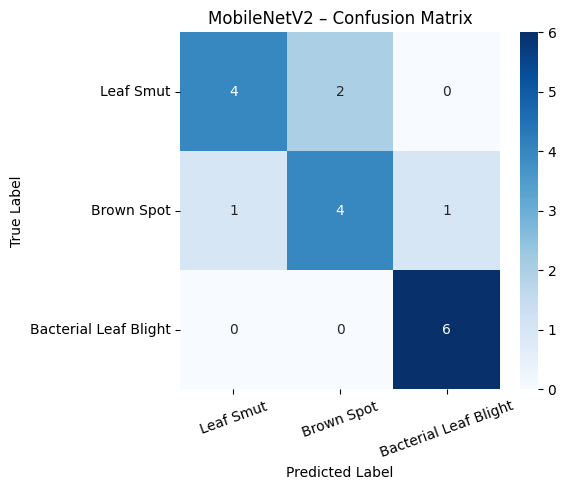

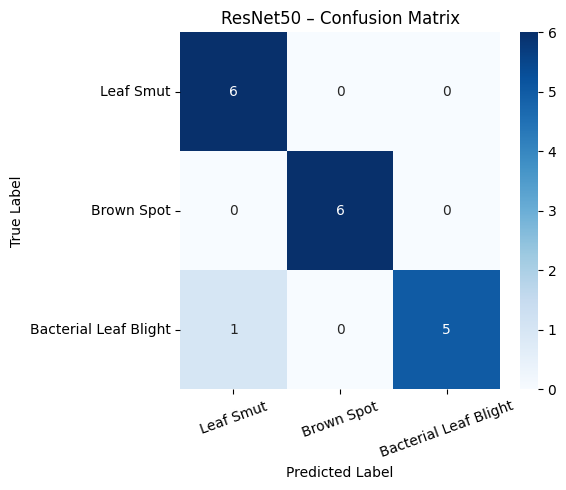

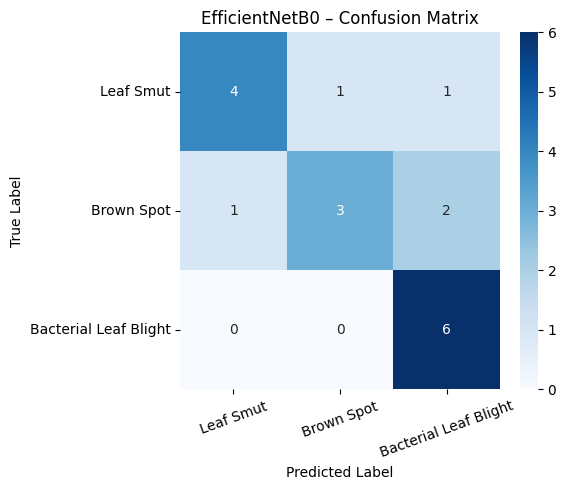

In [31]:
for name, result in evaluation_results.items():
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        result["Confusion Matrix"],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=EXPECTED_CLASSES,
        yticklabels=EXPECTED_CLASSES
    )
    plt.title(f"{name} – Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks(rotation=20)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 21. Model Performance Comparison

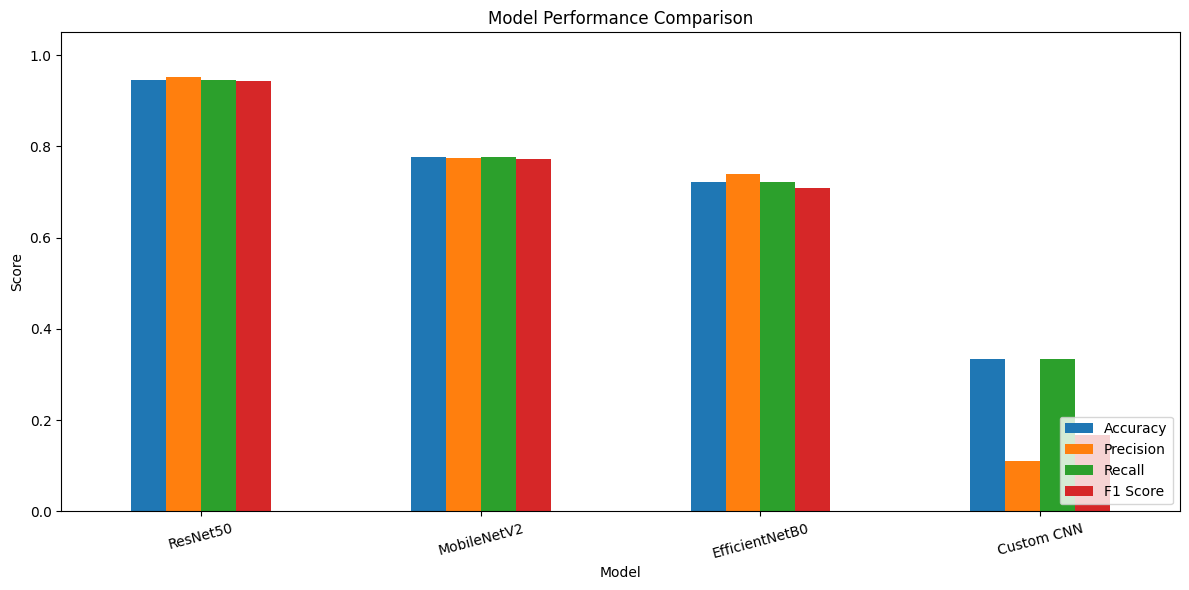

In [32]:
comparison_metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

plot_df = results_df.set_index("Model")[comparison_metrics]
ax = plot_df.plot(kind="bar", figsize=(12, 6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 22. Model Selection for the Project

The final model should not be selected from accuracy alone. This notebook compares predictive performance with model size using a clearly stated project-level heuristic.

The selection score is:
$$
\boxed{\text{Production Score} = 0.80(\text{F1 Score}) + 0.10(\text{Model Size Efficiency}) + 0.10(\text{Inference Efficiency})}
$$

This score is used only to rank the models for this capstone project. A real deployment decision would additionally require external validation, latency requirements, memory constraints, and field testing.

In [39]:
# ============================================================
# Balanced Model Selection
# ============================================================

rank_df = results_df.copy()

# ------------------------------------------------------------
# 1. Gentle model-size efficiency
# ------------------------------------------------------------
min_params = rank_df["Parameters"].min()

rank_df["Model Size Efficiency"] = (
    1 / np.sqrt(rank_df["Parameters"] / min_params)
)

# ------------------------------------------------------------
# 2. Inference-time efficiency
# ------------------------------------------------------------
min_time = rank_df["Inference Time per Image (sec)"].min()
max_time = rank_df["Inference Time per Image (sec)"].max()

if max_time == min_time:
    rank_df["Inference Efficiency"] = 1.0
else:
    rank_df["Inference Efficiency"] = 1 - (
        (rank_df["Inference Time per Image (sec)"] - min_time) /
        (max_time - min_time)
    )

# ------------------------------------------------------------
# 3. Balanced Production Score
#
# 80% = Disease classification performance
# 10% = Model-size efficiency
# 10% = Inference efficiency
# ------------------------------------------------------------
rank_df["Production Score"] = (
    0.80 * rank_df["F1 Score"] +
    0.10 * rank_df["Model Size Efficiency"] +
    0.10 * rank_df["Inference Efficiency"]
)

# ------------------------------------------------------------
# 4. Rank models
# ------------------------------------------------------------
rank_df = rank_df.sort_values(
    "Production Score",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 5. Display
# ------------------------------------------------------------
display(
    rank_df[[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Parameters",
        "Inference Time per Image (sec)",
        "Model Size Efficiency",
        "Inference Efficiency",
        "Production Score"
    ]].style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Inference Time per Image (sec)": "{:.4f}",
        "Model Size Efficiency": "{:.4f}",
        "Inference Efficiency": "{:.4f}",
        "Production Score": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 6. Select best model
# ------------------------------------------------------------
best_model_name = rank_df.iloc[0]["Model"]
best_model = models_to_build[best_model_name]

print(f"Recommended model: {best_model_name}")

,Model,Accuracy,Precision,Recall,F1 Score,Parameters,Inference Time per Image (sec),Model Size Efficiency,Inference Efficiency,Production Score
0,ResNet50,0.9444,0.9524,0.9444,0.9441,23593859,0.4389,0.1340,0.0000,0.7686
1,MobileNetV2,0.7778,0.7746,0.7778,0.7723,2261827,0.1993,0.4328,0.8326,0.7444
2,EfficientNetB0,0.7222,0.7389,0.7222,0.7091,4053414,0.3768,0.3233,0.2159,0.6212
3,Custom CNN,0.3333,0.1111,0.3333,0.1667,423619,0.1511,1.0000,1.0000,0.3333


Recommended model: ResNet50


## Final Model Selection

### Model Selection Formula

The final model was selected using a weighted performance-efficiency framework:
$$
\boxed{\text{Production Score} = 0.80(\text{F1 Score}) + 0.10(\text{Model Size Efficiency}) + 0.10(\text{Inference Efficiency})}
$$
Where:

- **F1 Score (80%)** – Represents the predictive performance of the model and is given the highest weight because accurate disease classification is the primary objective.
- **Model Size Efficiency (10%)** – Considers the computational footprint of the model while avoiding excessive penalization of larger models.
- **Inference Efficiency (10%)** – Considers the time required by the model to process an individual image, with faster inference receiving a higher score.

### Result

ResNet50 achieved the highest predictive performance with an **accuracy of 94.44%** and an **F1-score of 94.41%**. Although MobileNetV2 demonstrated substantially better model-size and inference efficiency, ResNet50 achieved the highest overall **Production Score of 0.7686** under the proposed weighted model-selection framework.

Therefore, **ResNet50 was selected as the final model** because its superior disease-classification performance outweighed its additional computational requirements.

## 23. Predict a New Rice Leaf Image

In [36]:
# ============================================================
# Prediction from an Image URL using the Best Model
# ============================================================

import requests
from io import BytesIO
from IPython.display import display

def preprocess_image_for_model(image_array, model_name):
    """
    Apply the same preprocessing used during model training.
    """
    image_array = image_array.astype("float32")

    if model_name == "Custom CNN":
        return image_array / 255.0

    elif model_name == "MobileNetV2":
        return mobilenet_preprocess(image_array)

    elif model_name == "ResNet50":
        return resnet_preprocess(image_array)

    elif model_name == "EfficientNetB0":
        # EfficientNetB0 handles preprocessing internally
        return image_array

    else:
        raise ValueError(f"Unknown model: {model_name}")


def predict_image_from_url(image_url, model=best_model, model_name=best_model_name):
    """
    Download a rice leaf image from a URL and predict its disease
    using the best model selected during model comparison.
    """

    # --------------------------------------------------------
    # 1. Validate URL
    # --------------------------------------------------------
    if not image_url.startswith(("http://", "https://")):
        raise ValueError(
            "Please enter a valid image URL beginning with http:// or https://"
        )

    print("Downloading image...")

    try:
        response = requests.get(
            image_url,
            timeout=15,
            headers={
                "User-Agent": "Mozilla/5.0"
            }
        )
        response.raise_for_status()

    except requests.exceptions.RequestException as e:
        raise RuntimeError(f"Unable to download image: {e}")

    # --------------------------------------------------------
    # 2. Open image
    # --------------------------------------------------------
    try:
        img = Image.open(BytesIO(response.content)).convert("RGB")
    except Exception as e:
        raise ValueError(
            "The URL does not appear to contain a valid image."
        ) from e

    # --------------------------------------------------------
    # 3. Resize image
    # --------------------------------------------------------
    resized = img.resize(IMG_SIZE)

    # Convert image to NumPy array
    arr = np.array(resized)

    # --------------------------------------------------------
    # 4. Apply model-specific preprocessing
    # --------------------------------------------------------
    arr = preprocess_image_for_model(arr, model_name)

    # Add batch dimension
    arr = np.expand_dims(arr, axis=0)

    # --------------------------------------------------------
    # 5. Prediction
    # --------------------------------------------------------
    probabilities = model.predict(arr, verbose=0)[0]

    predicted_idx = int(np.argmax(probabilities))
    predicted_class = EXPECTED_CLASSES[predicted_idx]
    confidence = float(probabilities[predicted_idx])

    # --------------------------------------------------------
    # 6. Display image and prediction
    # --------------------------------------------------------
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(
        f"Predicted Disease: {predicted_class}\n"
        f"Confidence: {confidence:.2%}",
        fontsize=14
    )
    plt.axis("off")
    plt.show()

    # --------------------------------------------------------
    # 7. Display probability for every class
    # --------------------------------------------------------
    prediction_df = pd.DataFrame({
        "Disease": EXPECTED_CLASSES,
        "Probability": probabilities
    })

    prediction_df = prediction_df.sort_values(
        "Probability",
        ascending=False
    ).reset_index(drop=True)

    display(
        prediction_df.style.format({
            "Probability": "{:.2%}"
        })
    )

    # --------------------------------------------------------
    # 8. Print final result
    # --------------------------------------------------------
    print("=" * 60)
    print("RICE LEAF DISEASE PREDICTION")
    print("=" * 60)
    print(f"Model Used : {model_name}")
    print(f"Prediction : {predicted_class}")
    print(f"Confidence : {confidence:.2%}")
    print("=" * 60)

    return predicted_class, confidence, probabilities

Enter the URL of the rice leaf image: http://www.knowledgebank.irri.org/images/stories/leaf-scald.jpg


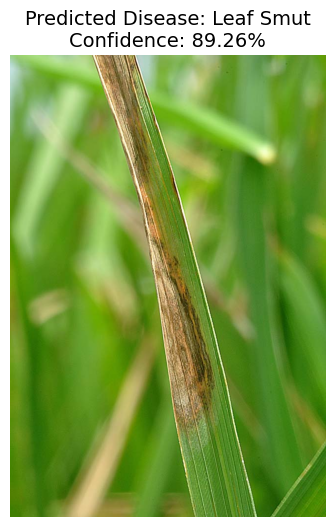

,Disease,Probability
0,Leaf Smut,89.26%
1,Brown Spot,5.85%
2,Bacterial Leaf Blight,4.89%


RICE LEAF DISEASE PREDICTION
Model Used : ResNet50
Prediction : Leaf Smut
Confidence : 89.26%


In [47]:
# ============================================================
# USER INPUT
# ============================================================

#Example:
#1. https://apps.lucidcentral.org/pppw_v10/images/entities/rice_brown_leaf_spot_427/cochliobolus.jpg
#2. http://www.knowledgebank.irri.org/images/stories/leaf-scald.jpg
#3. http://eagri.org/eagri50/PATH272/lecture01/0012.jpg


image_url = input("Enter the URL of the rice leaf image: ")

prediction = predict_image_from_url(
    image_url,
    model=best_model,
    model_name=best_model_name
)

## 24. Analyze Data Augmentation

### Why augmentation was used
The dataset is extremely small, with only 40 original images per class. A deep learning model can easily memorize these examples instead of learning disease-related visual features.

### Techniques used
- **Rotation:** helps the model recognize leaves at different orientations.
- **Width/height shifts:** reduces dependence on exact leaf position.
- **Zoom:** improves robustness to different camera distances.
- **Shear:** introduces mild geometric variation.
- **Horizontal flip:** provides orientation variation where biologically acceptable.
- **Rescaling:** converts pixel values from approximately 0–255 to 0–1.


Augmentation is applied only to the training data. Validation and test images remain unaugmented so that evaluation represents the model's performance on unseen images.

## 25. Challenges Faced and Solutions

## Challenges and Techniques Used

- **Very small dataset**
  - **Impact:** High risk of overfitting and poor generalization.
  - **Technique Used:** Transfer learning + data augmentation.
  - **Reason:** Pretrained visual features reduce the amount of data required to learn useful representations.

- **Only 40 images per class**
  - **Impact:** Limited statistical reliability.
  - **Technique Used:** Stratified train/validation/test split.
  - **Reason:** Maintains representation of all disease classes across subsets.

- **Different image dimensions**
  - **Impact:** Neural networks require consistent input dimensions.
  - **Technique Used:** Resize images to **224 × 224**.
  - **Reason:** Provides a consistent input shape for all models.

- **Potential overfitting**
  - **Impact:** Training performance may become much higher than validation performance.
  - **Technique Used:** Dropout + EarlyStopping + ReduceLROnPlateau.
  - **Reason:** Regularization and controlled training help reduce memorization.

- **Disease classes may contain visually similar symptoms**
  - **Impact:** Some classes can be confused.
  - **Technique Used:** Confusion matrix + per-class precision/recall/F1.
  - **Reason:** Shows which disease pairs are most difficult to distinguish.

- **Production resource constraints**
  - **Impact:** Large models may be slower or harder to deploy.
  - **Technique Used:** Compare MobileNetV2 with larger models.
  - **Reason:** Lightweight architectures can offer a better accuracy-efficiency tradeoff.

- **Small test set**
  - **Impact:** A single accuracy value can be unstable.
  - **Technique Used:** Report multiple metrics and explicitly document the limitation.
  - **Reason:** F1, precision, recall, and confusion matrices provide additional evidence.

## 26. Production Recommendation

### Recommended decision framework
The final production model should be selected using:

1. F1 score and recall – important for disease classification.
2. Per-class performance – one disease should not be ignored because of aggregate accuracy.
3. Confusion matrix – identifies clinically/agronomically important class confusion.
4. Model size – important for mobile/edge deployment.
5. Inference time – important for real-time applications.
6. Robustness on a larger independent dataset – essential before actual deployment.

### Project recommendation
The model selected in the previous section is the recommended candidate under the notebook's performance-efficiency heuristic. However, **deployment should not be considered final using this 120-image dataset alone**. A larger dataset containing images from different farms, cameras, lighting conditions, backgrounds, rice varieties, and disease severity levels should be collected and used for external validation.

## 27. Final Conclusion

In [49]:
best_row = rank_df.iloc[0]

print(f'''
FINAL PROJECT SUMMARY
=====================

Dataset:
- Total valid images: {len(image_df)}
- Classes: {", ".join(EXPECTED_CLASSES)}
- Expected images per class: 40

Models compared:
- Custom CNN
- MobileNetV2
- ResNet50
- EfficientNetB0

Recommended candidate under the project comparison heuristic:
- {best_row["Model"]}

Measured test metrics on this split:
- Accuracy : {best_row["Accuracy"]:.4f}
- Precision: {best_row["Precision"]:.4f}
- Recall   : {best_row["Recall"]:.4f}
- F1 Score : {best_row["F1 Score"]:.4f}

Main techniques:
- Stratified data splitting
- Image resizing and normalization
- Training-only data augmentation
- Transfer learning
- Dropout
- Early stopping
- Learning-rate reduction
- Confusion-matrix and classification-report analysis
- Model-size and inference-time comparison

Major limitation:
The dataset contains only 120 images. Therefore, the results are appropriate for this capstone comparison but should not be treated as proof of production-level generalization. External validation on a substantially larger and more diverse dataset is recommended before deployment.
''')


FINAL PROJECT SUMMARY

Dataset:
- Total valid images: 119
- Classes: Leaf Smut, Brown Spot, Bacterial Leaf Blight
- Expected images per class: 40

Models compared:
- Custom CNN
- MobileNetV2
- ResNet50
- EfficientNetB0

Recommended candidate under the project comparison heuristic:
- ResNet50

Measured test metrics on this split:
- Accuracy : 0.9444
- Precision: 0.9524
- Recall   : 0.9444
- F1 Score : 0.9441

Main techniques:
- Stratified data splitting
- Image resizing and normalization
- Training-only data augmentation
- Transfer learning
- Dropout
- Early stopping
- Learning-rate reduction
- Confusion-matrix and classification-report analysis
- Model-size and inference-time comparison

Major limitation:
The dataset contains only 120 images. Therefore, the results are appropriate for this capstone comparison but should not be treated as proof of production-level generalization. External validation on a substantially larger and more diverse dataset is recommended before deployment.

